In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt
from gwpy.timeseries import TimeSeries
from matplotlib.colors import Normalize
from gwtorch.modules.gw_utils import generate_prior, generate_waveform, display_qtransform, pad_to_shape

In [2]:
sample = generate_prior(1)

In [3]:
sample[0]['eccentricity'] = 0.3
sample[0]['Log_Mlz'] = 4
sample[0]['yl'] = 0.3

In [4]:
sample

[{'mass_ratio': np.float64(0.19384023520259766),
  'chirp_mass': np.float64(34.51337696503736),
  'dec': np.float64(0.9796301417006255),
  'ra': np.float64(0.16742568363518345),
  'spin1z': np.float64(-0.1095728566597951),
  'spin2z': np.float64(-0.7662327278196306),
  'eccentricity': 0.3,
  'anomaly': np.float64(4.824275576299654),
  'coa_phase': np.float64(5.772164543163644),
  'polarization': np.float64(2.5951427809352037),
  'Log_Mlz': 4,
  'yl': 0.3,
  'snr': np.float64(10.30057716819995)}]

# SNR = 10

In [5]:
sample

[{'mass_ratio': np.float64(0.19384023520259766),
  'chirp_mass': np.float64(34.51337696503736),
  'dec': np.float64(0.9796301417006255),
  'ra': np.float64(0.16742568363518345),
  'spin1z': np.float64(-0.1095728566597951),
  'spin2z': np.float64(-0.7662327278196306),
  'eccentricity': 0.3,
  'anomaly': np.float64(4.824275576299654),
  'coa_phase': np.float64(5.772164543163644),
  'polarization': np.float64(2.5951427809352037),
  'Log_Mlz': 4,
  'yl': 0.3,
  'snr': np.float64(10.30057716819995)}]

In [6]:
# def generate_plot(sample):
#     for k in [10, 30, 50]:
#         sample[0]['snr'] = k

#         n_rows = len(sample)
#         n_cols = 3  # ecc, lensed, unlensed

#         fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3 * n_rows))

#         # Handle case when n_rows == 1
#         if n_rows == 1:
#             axes = np.expand_dims(axes, axis=0)

#         for i in range(n_rows):
#             ecc_dict, lens_dict, unlens_dict, mass1, mass2, m_lens, y_lens = generate_waveform(
#                 0, sample[i],
#                 display=False,
#                 SEED={'ecc_seed': 0, 'lens_seed': 0, 'unlens_seed': 0}
#             )

#             ecc = ecc_dict['ecc_signal']
#             lens = lens_dict['lensed_signal']
#             unlens = unlens_dict['unlensed_signal']

#             # Q-transforms
#             qt_ecc = np.abs(display_qtransform(ecc, display=False).data).T
#             qt_lens = np.abs(display_qtransform(lens, display=False).data).T
#             qt_unlens = np.abs(display_qtransform(unlens, display=False).data).T

#             # Common shape across the three
#             max_shape = (
#                 max(qt_ecc.shape[0], qt_lens.shape[0], qt_unlens.shape[0]),
#                 max(qt_ecc.shape[1], qt_lens.shape[1], qt_unlens.shape[1])
#             )

#             qt_ecc = pad_to_shape(qt_ecc, max_shape)
#             qt_lens = pad_to_shape(qt_lens, max_shape)
#             qt_unlens = pad_to_shape(qt_unlens, max_shape)

#             # Shared normalization per row (IMPORTANT)
#             combined = np.concatenate([qt_ecc, qt_lens, qt_unlens])
#             norm = Normalize(vmin=combined.min(), vmax=combined.max())

#             plots = [qt_ecc, qt_lens, qt_unlens]
#             titles = ["ECCENTRIC", "LENSED", "UNLENSED"]

#             for j in range(n_cols):
#                 ax = axes[i, j]
#                 ax.imshow(norm(plots[j]), aspect='auto', origin='lower')
#                 ax.axis('off')

#                 if i == 0:
#                     ax.set_title(titles[j], fontsize=12)

#         plt.suptitle(f"SNR = {k}", fontsize=16)
#         plt.tight_layout()
#         plt.show()


def generate_plot(sample, save_path="/home/qubit/Downloads/plot_snr50.png"):
    snr = 50

    n_samples = len(sample)
    n_cols = 1              # only one SNR
    n_rows = n_samples * 3  # ECC, LENS, UNLENS per sample

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, 5 * n_rows))

    # Handle edge cases
    if n_rows == 1:
        axes = np.array([[axes]])
    elif n_cols == 1:
        axes = np.expand_dims(axes, axis=1)

    sample[0]['snr'] = snr

    for i in range(n_samples):
        ecc_dict, lens_dict, unlens_dict, mass1, mass2, m_lens, y_lens = generate_waveform(
            0, sample[i],
            display=False,
            SEED={'ecc_seed': 0, 'lens_seed': 0, 'unlens_seed': 0}
        )

        ecc = ecc_dict['ecc_signal']
        lens = lens_dict['lensed_signal']
        unlens = unlens_dict['unlensed_signal']

        qt_ecc = np.abs(display_qtransform(ecc, display=False).data).T
        qt_lens = np.abs(display_qtransform(lens, display=False).data).T
        qt_unlens = np.abs(display_qtransform(unlens, display=False).data).T

        max_shape = (
            max(qt_ecc.shape[0], qt_lens.shape[0], qt_unlens.shape[0]),
            max(qt_ecc.shape[1], qt_lens.shape[1], qt_unlens.shape[1])
        )

        qt_ecc = pad_to_shape(qt_ecc, max_shape)
        qt_lens = pad_to_shape(qt_lens, max_shape)
        qt_unlens = pad_to_shape(qt_unlens, max_shape)

        combined = np.concatenate([qt_ecc, qt_lens, qt_unlens])
        norm = Normalize(vmin=combined.min(), vmax=combined.max())

        plots = [qt_ecc, qt_lens, qt_unlens]
        labels = ["ECCENTRIC", "LENSED", "UNLENSED"]

        for j in range(3):
            row = i * 3 + j
            ax = axes[row, 0]

            ax.imshow(norm(plots[j]), aspect='auto', origin='lower')
            ax.axis('off')

            # Label each image (clear + centered)
            ax.text(
                0.02, 0.9, labels[j],
                transform=ax.transAxes,
                fontsize=20,
                color='white',
                bbox=dict(facecolor='black', alpha=0.6, pad=2)
            )

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close(fig)

In [7]:
generate_plot(sample)

# -------------------------------------------------------

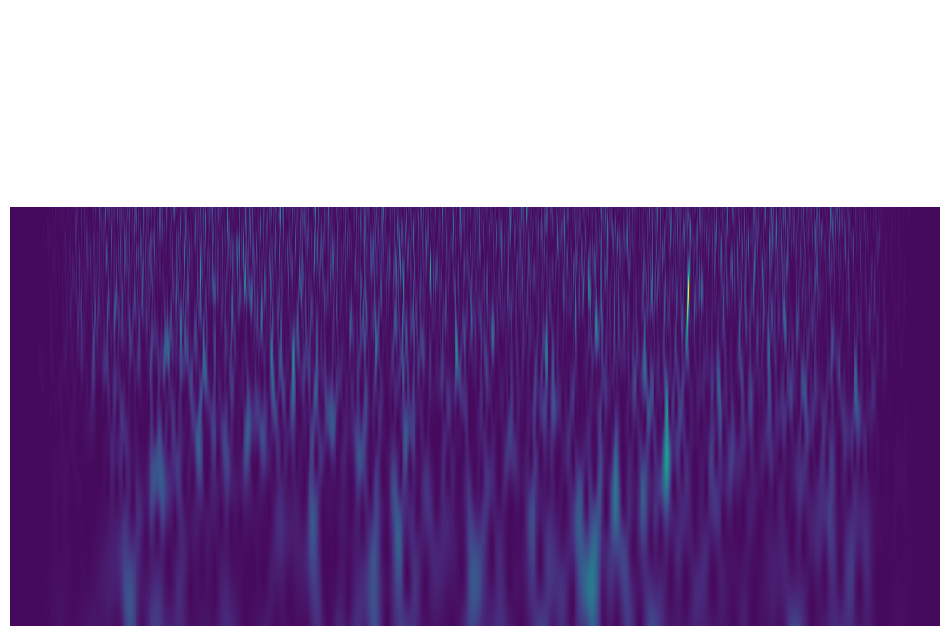

In [7]:
stacked_q = []
for i in range(len(sample)):
    ecc_dict, lens_dict, unlens_dict, mass1, mass2, m_lens, y_lens = generate_waveform(0, sample[i], display=False, SEED={'ecc_seed': 0, 'lens_seed': 0, 'unlens_seed': 0})
    ecc = ecc_dict['ecc_signal']
    qt = display_qtransform(ecc)
    stacked_q.append(np.abs(qt.data).T)

In [8]:
max_shape = (
    max(q.shape[0] for q in stacked_q),
    max(q.shape[1] for q in stacked_q)
)

padded_q = [pad_to_shape(q, max_shape) for q in stacked_q]
normed = [Normalize()(q) for q in padded_q]

stacked = np.stack(normed, axis=0)
stacked_img = np.transpose(stacked, (1, 2, 0))

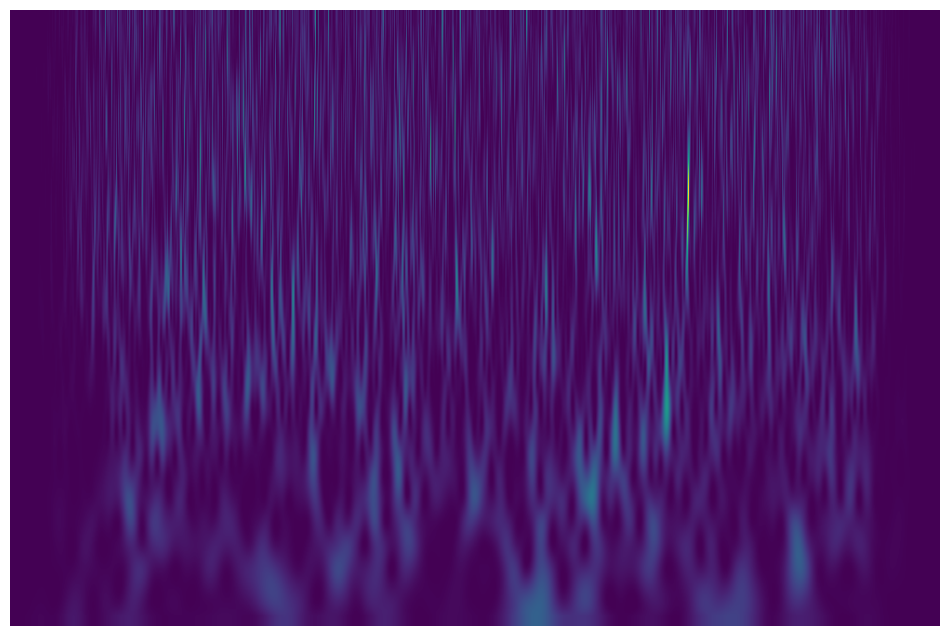

In [9]:
plt.figure(figsize=(12, 8), frameon=False)
plt.imshow(stacked_img, aspect='auto', origin='lower')
plt.grid('off')
plt.axis('off')
plt.show()